# Deterministic Plotting: One Grade Schematic per Image

For 5 randomly sampled graded images, this notebook retrieves the grading
model's "physics interpretation" -- the structured, per-rubric-rule verdict
it returned for every rule (`quantity`, `relation`, `expected` threshold, and
crucially the **actual credit it awarded** vs. the rule's maximum,
`awarded / points`) -- and passes the whole rule list for that image to a
separate Python script, `schematic_plot.py`, which deterministically
constructs **one combined plot per image**: a single continuous timeline made
of one segment per rubric rule, concatenated in rubric order.

**The unsatisfied part is colored.** Each segment is colored on a
red-to-green scale by that rule's actual `awarded / points` credit fraction:
a fully unsatisfied rule's segment is red, a fully satisfied one is green,
and partial credit falls in between (e.g. 1/3 credit sketches a shade closer
to red, colored and positioned proportionally, not a binary flip). This means
the unsatisfied part of the grade is immediately visible, by color, on the
one plot -- not spread across separate per-rule panels.

**Partial credit from the model response vs. the actual credit.** Every
rule's segment is labeled with its id and credit percentage directly on the
curve, and a caption block underneath lists, per rule, both
`partial_credit_reason` (the model's own free-text justification for *why*
it gave the credit it did) and `observed` (what it says it saw) next to the
actual `awarded / points` number -- so the qualitative text and the
quantitative credit (and the schematic's color/position) can all be checked
against each other, and against the real image, at a glance.

**What "deterministic" means here:** the plot is a pure function of the
rules' own numbers (`quantity`, `relation`, `expected`, `awarded`, `points`).
The same set of rules always produces the exact same schematic -- no
randomness, no new model calls. Only the *sample selection* uses randomness,
and that is seeded (`random_state=42`) so the same 5 images are picked every
time this notebook is re-run.

**What the schematic is -- and is not.** It is *not* a reconstruction of the
real submitted curve (the notebook never looks at pixel content beyond
displaying the original image alongside it, and the y-axis mixes value/
slope/curvature units across segments, so it is explicitly labeled
"illustrative, not to scale"). It is a sketch of what the rubric's own
credit decisions imply, laid out as one timeline, so its shape and coloring
can be visually sanity-checked against the real image and the model's own
written reasoning.

Source data: `output/grading_results_standalone/intermediate_step_rule_grades.jsonl`
(the **standalone_submission** policy -- experiment 2, no reference image or
step hints shown to the grader, partial credit justified strictly by
closeness to each rule's own threshold; see
`reports_and_presentations/04_methods_and_primers/notebook_inputs_reference.docx` for the full schema).

Each figure also includes the trajectory's own `panel.png` (built by the
generation pipeline): a full 00-donor-to-06-reference-answer strip, so the
single graded image and its grade schematic can be seen in the context of
the whole correction sequence, not in isolation.

Run from the `diffusion_module_v2/` project root.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image as IPyImage, display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "deterministic_plotting"))
from schematic_plot import build_sample_figure, credit_fraction

GRADING_FILE = ROOT / "output" / "grading_results_standalone" / "intermediate_step_rule_grades.jsonl"
FIG_DIR = ROOT / "deterministic_plotting" / "figures"
SAMPLE_SEED = 42
N_SAMPLES = 5

df = pd.read_json(GRADING_FILE, lines=True)
print(f"{len(df)} graded images available in {GRADING_FILE.relative_to(ROOT)}")

6000 graded images available in output\grading_results_standalone\intermediate_step_rule_grades.jsonl


## 1. Draw 5 random samples (seeded, reproducible)

In [3]:
sample = df.sample(n=N_SAMPLES, random_state=SAMPLE_SEED).reset_index(drop=True)
sample[["exercise", "round", "source_exercise", "instance", "step_file", "score_ratio"]]

,exercise,round,source_exercise,instance,step_file,score_ratio
0,2,1,3,instance_023,05_labels_fixed.png,1.0
1,3,2,4,instance_017,03_main_trend_corrected.png,0.5
2,1,1,3,instance_009,05_labels_fixed.png,1.0
3,2,2,1,instance_028,02_more_curve_adjusted.png,0.6
4,4,2,2,instance_012,01_slight_correction.png,0.3


## 2. Retrieve each image's physics interpretation and build its grade schematic

`record["rules"]` *is* the model's physics interpretation for that image: one entry per rubric rule, each carrying the quantity it checked, the relation and threshold it tested against, the actual credit it awarded out of that rule's points, and its own free-text `observed` description plus `partial_credit_reason` justification. `build_sample_figure` (in `schematic_plot.py`) is the "python script" the whole rule list gets passed to, producing one combined grade schematic for the image.

In [5]:
figure_paths = []
for i, row in sample.iterrows():
    record = row.to_dict()
    out_path = FIG_DIR / f"sample_{i+1}_ex{record['exercise']}_{record['instance']}_{Path(record['step_file']).stem}.png"
    figure_paths.append(build_sample_figure(record, out_path))
    print(f"sample {i+1}: {out_path.name}")

sample 1: sample_1_ex2_instance_023_05_labels_fixed.png
sample 2: sample_2_ex3_instance_017_03_main_trend_corrected.png
sample 3: sample_3_ex1_instance_009_05_labels_fixed.png
sample 4: sample_4_ex2_instance_028_02_more_curve_adjusted.png
sample 5: sample_5_ex4_instance_012_01_slight_correction.png


## 3. The 5 samples: real image + one combined grade schematic, side by side

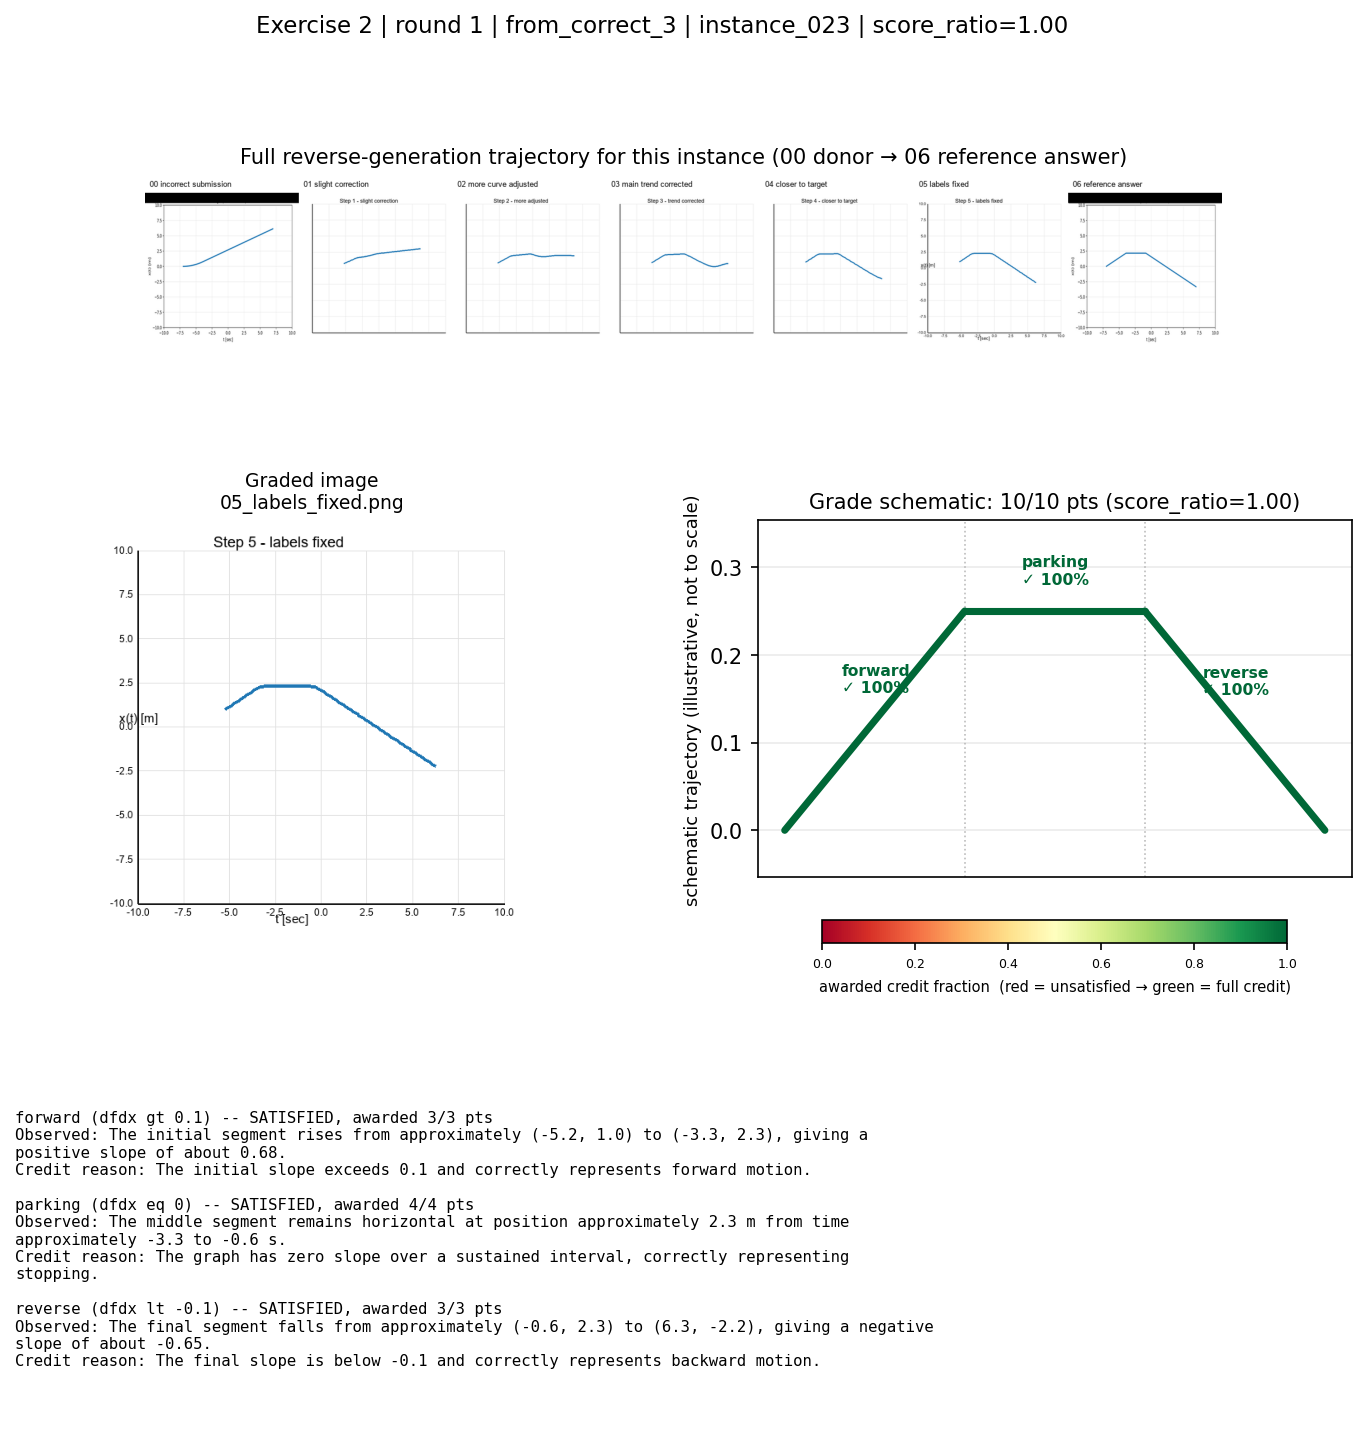

Sample 1: Exercise 2, round 1, from_correct_3, instance_023, 05_labels_fixed.png
score_ratio=1.00  |  3/3 rules at full credit, avg credit fraction=100%
feedback: The labeled position-versus-time graph correctly shows forward motion, a sustained stop, and backward motion through positive, zero, and negative slopes.


In [7]:
record = sample.iloc[0].to_dict()
fractions = [credit_fraction(r) for r in record["rules"]]
avg_fraction = sum(fractions) / len(fractions)
n_full_credit = sum(f >= 0.999 for f in fractions)
print(
    f"Sample 1: Exercise {record['exercise']}, round {record['round']}, "
    f"from_correct_{record['source_exercise']}, {record['instance']}, {record['step_file']}\n"
    f"score_ratio={record['score_ratio']:.2f}  |  {n_full_credit}/{len(fractions)} rules at full credit, "
    f"avg credit fraction={avg_fraction*100:.0f}%\n"
    f"feedback: {record['feedback']}"
)
display(IPyImage(filename=str(figure_paths[0])))

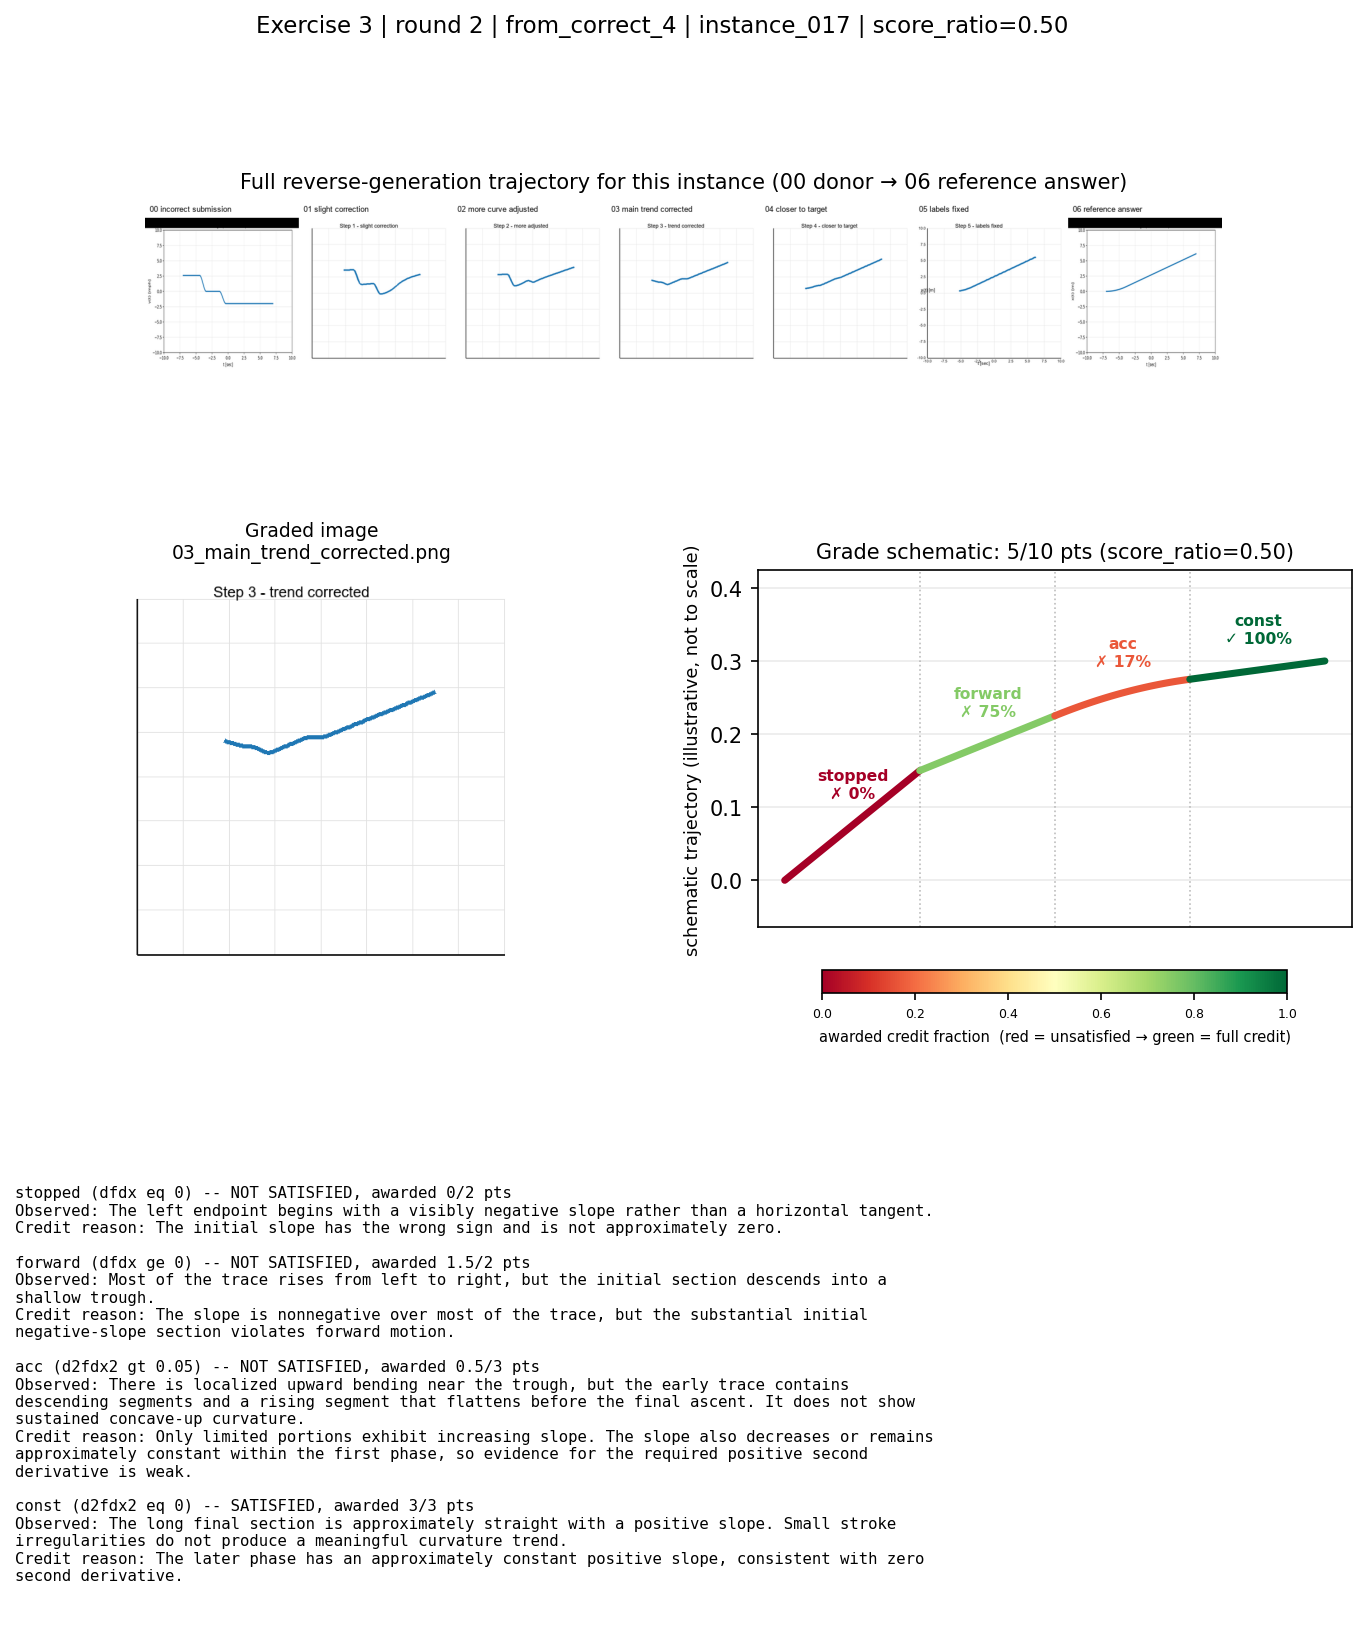

Sample 2: Exercise 3, round 2, from_correct_4, instance_017, 03_main_trend_corrected.png
score_ratio=0.50  |  1/4 rules at full credit, avg credit fraction=48%
feedback: The final constant-speed segment is correct. Begin with a horizontal tangent and follow it with a consistently concave-up rise, without the initial dip or intermediate flattening. Label the axes as time and position, and remove the process-oriented title.


In [8]:
record = sample.iloc[1].to_dict()
fractions = [credit_fraction(r) for r in record["rules"]]
avg_fraction = sum(fractions) / len(fractions)
n_full_credit = sum(f >= 0.999 for f in fractions)
print(
    f"Sample 2: Exercise {record['exercise']}, round {record['round']}, "
    f"from_correct_{record['source_exercise']}, {record['instance']}, {record['step_file']}\n"
    f"score_ratio={record['score_ratio']:.2f}  |  {n_full_credit}/{len(fractions)} rules at full credit, "
    f"avg credit fraction={avg_fraction*100:.0f}%\n"
    f"feedback: {record['feedback']}"
)
display(IPyImage(filename=str(figure_paths[1])))

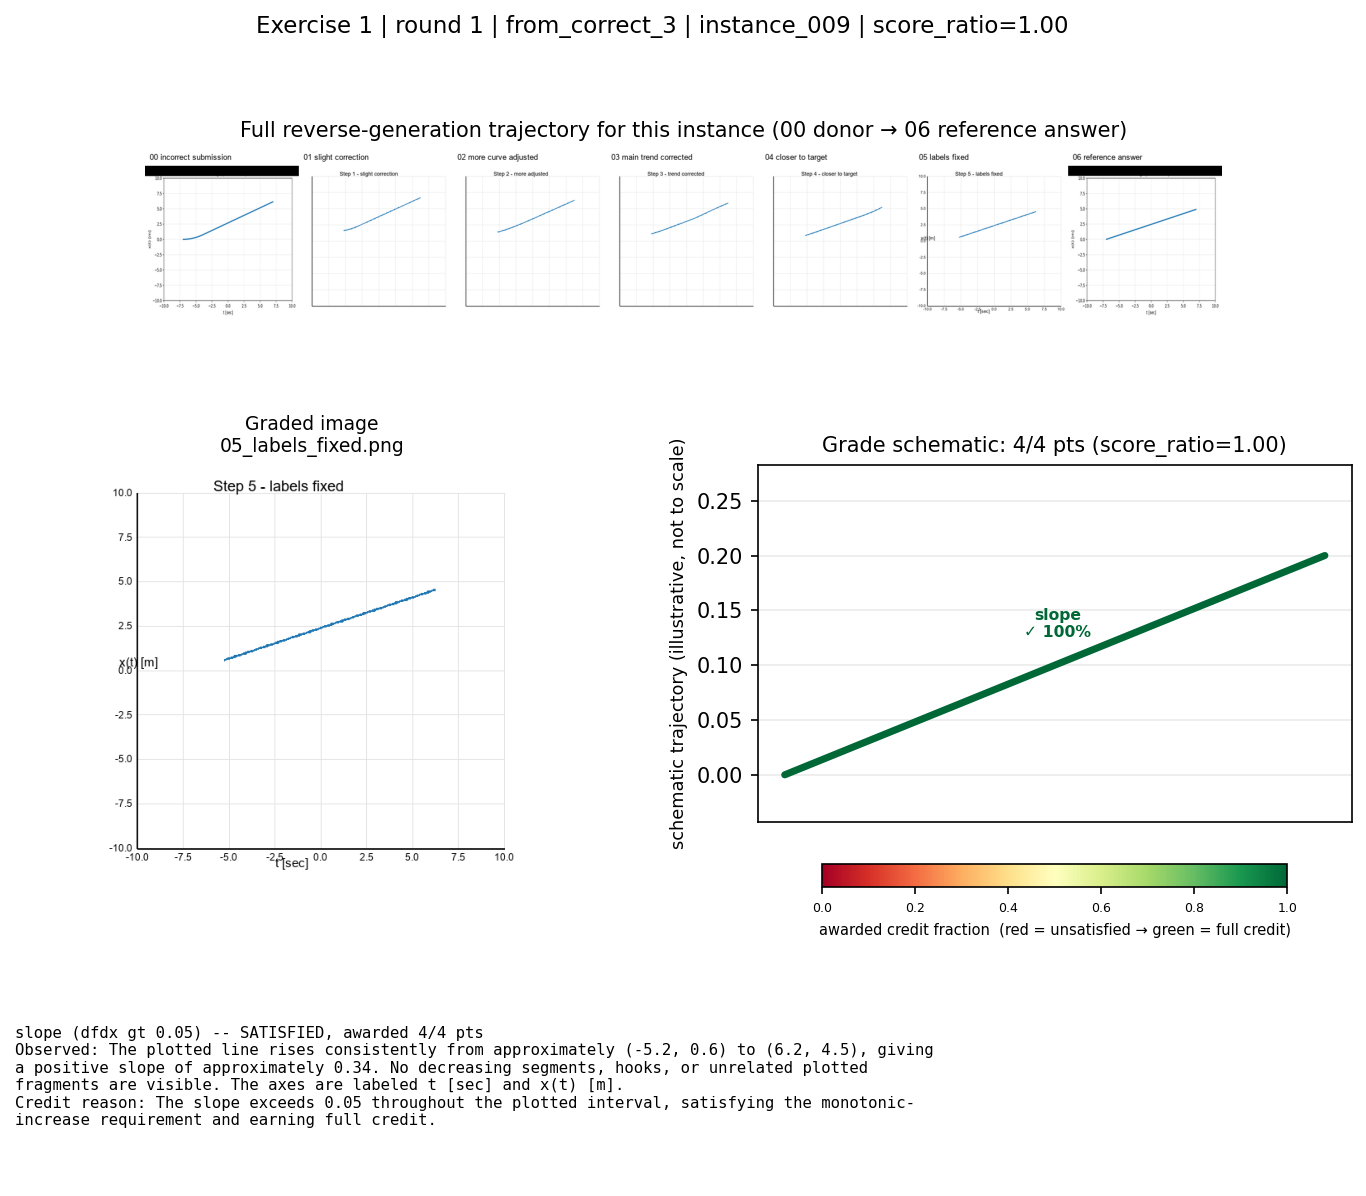

Sample 3: Exercise 1, round 1, from_correct_3, instance_009, 05_labels_fixed.png
score_ratio=1.00  |  1/1 rules at full credit, avg credit fraction=100%
feedback: The graph increases throughout its plotted interval and has correctly labeled axes.


In [9]:
record = sample.iloc[2].to_dict()
fractions = [credit_fraction(r) for r in record["rules"]]
avg_fraction = sum(fractions) / len(fractions)
n_full_credit = sum(f >= 0.999 for f in fractions)
print(
    f"Sample 3: Exercise {record['exercise']}, round {record['round']}, "
    f"from_correct_{record['source_exercise']}, {record['instance']}, {record['step_file']}\n"
    f"score_ratio={record['score_ratio']:.2f}  |  {n_full_credit}/{len(fractions)} rules at full credit, "
    f"avg credit fraction={avg_fraction*100:.0f}%\n"
    f"feedback: {record['feedback']}"
)
display(IPyImage(filename=str(figure_paths[2])))

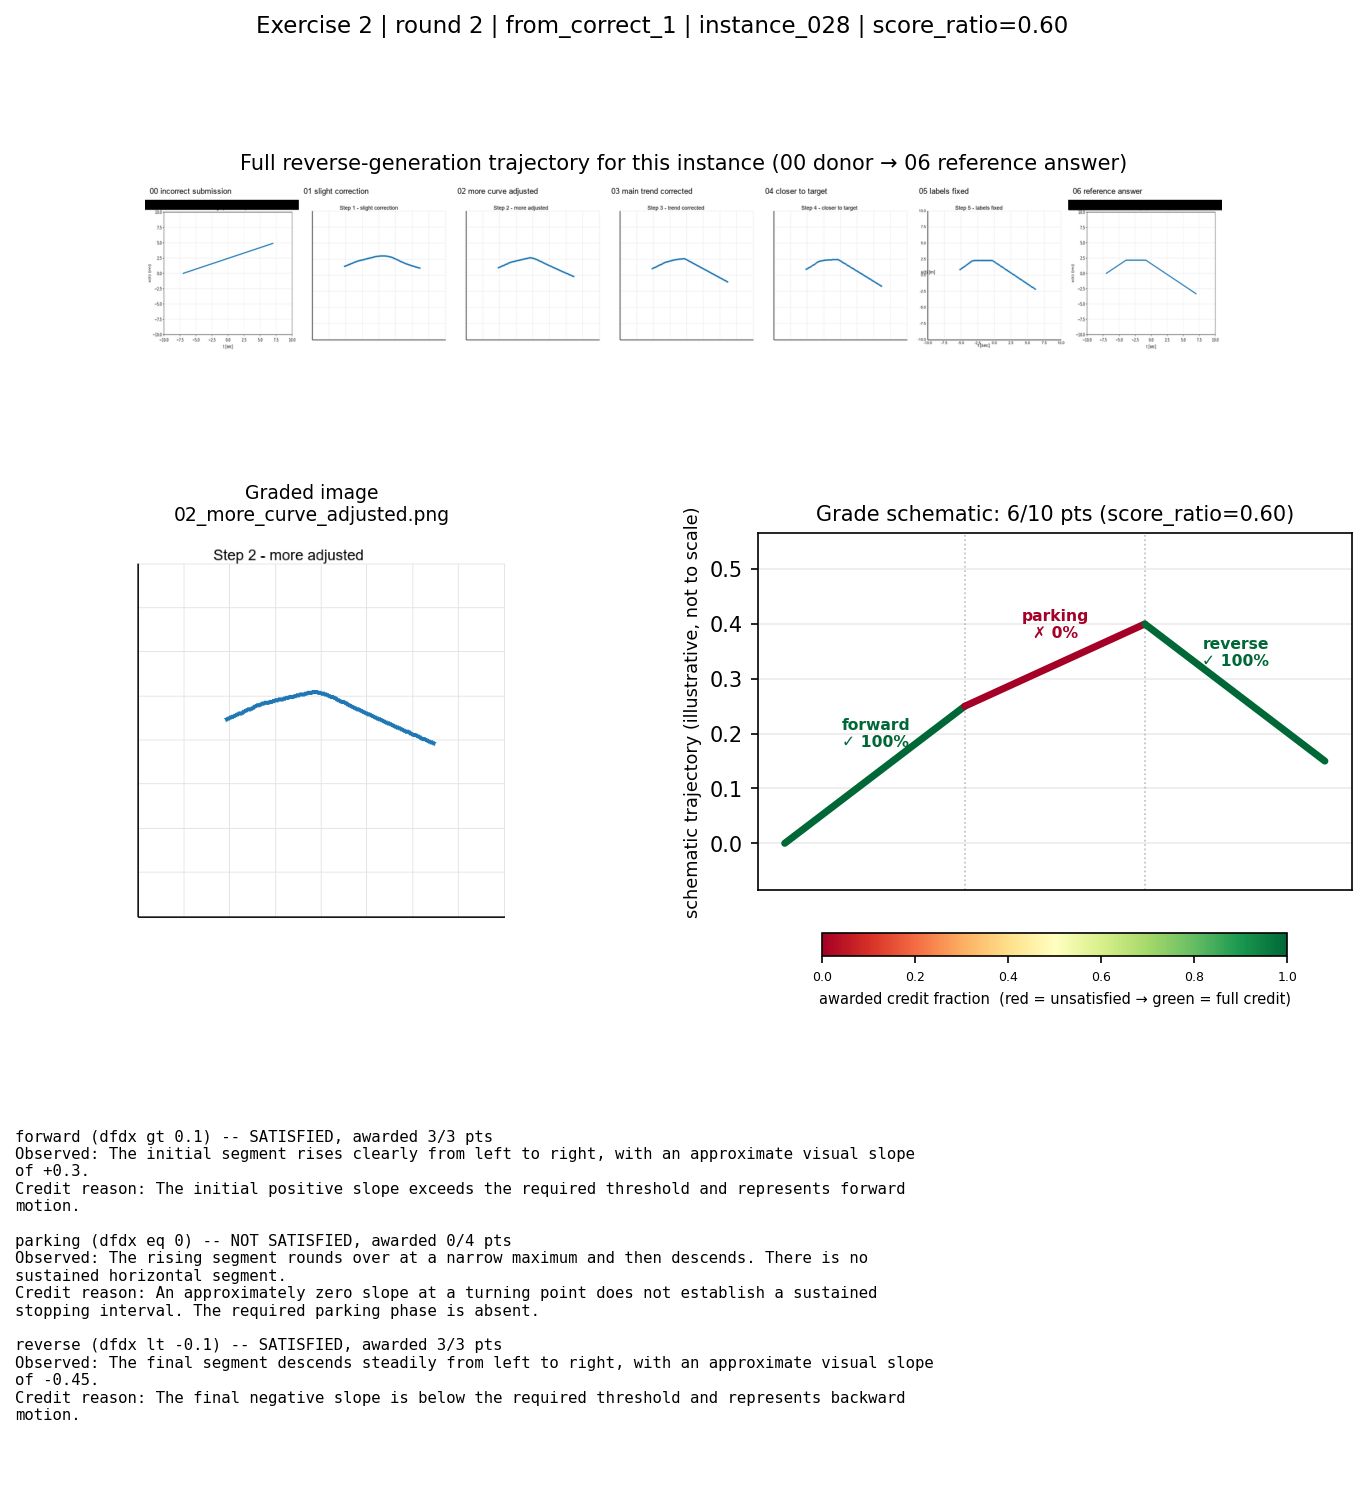

Sample 4: Exercise 2, round 2, from_correct_1, instance_028, 02_more_curve_adjusted.png
score_ratio=0.60  |  2/3 rules at full credit, avg credit fraction=67%
feedback: Forward and backward motion are shown correctly. Add a clearly horizontal interval between them to represent stopping for a sustained period.


In [10]:
record = sample.iloc[3].to_dict()
fractions = [credit_fraction(r) for r in record["rules"]]
avg_fraction = sum(fractions) / len(fractions)
n_full_credit = sum(f >= 0.999 for f in fractions)
print(
    f"Sample 4: Exercise {record['exercise']}, round {record['round']}, "
    f"from_correct_{record['source_exercise']}, {record['instance']}, {record['step_file']}\n"
    f"score_ratio={record['score_ratio']:.2f}  |  {n_full_credit}/{len(fractions)} rules at full credit, "
    f"avg credit fraction={avg_fraction*100:.0f}%\n"
    f"feedback: {record['feedback']}"
)
display(IPyImage(filename=str(figure_paths[3])))

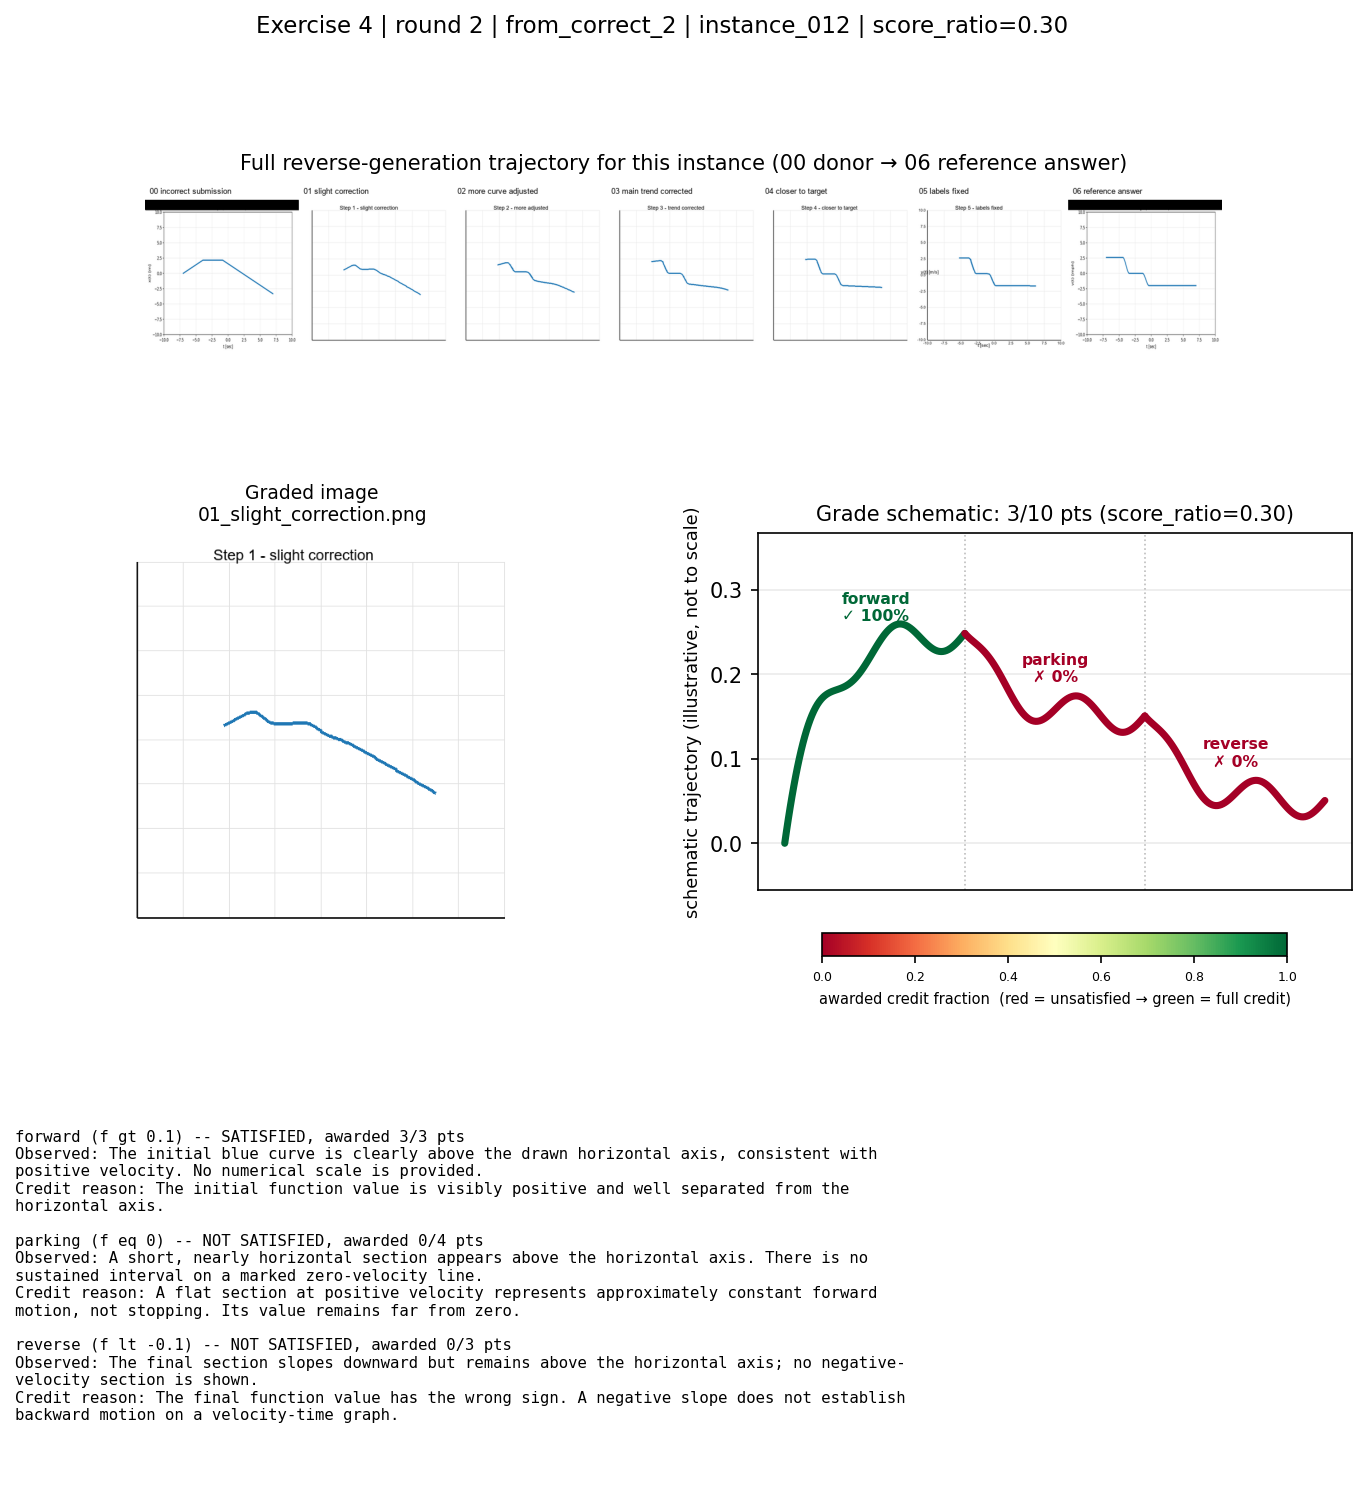

Sample 5: Exercise 4, round 2, from_correct_2, instance_012, 01_slight_correction.png
score_ratio=0.30  |  1/3 rules at full credit, avg credit fraction=33%
feedback: The graph shows positive velocity throughout, not forward motion followed by stopping and reversing. Label the axes as time and velocity, mark zero velocity, include a sustained interval at zero, and place the final section below zero.


In [11]:
record = sample.iloc[4].to_dict()
fractions = [credit_fraction(r) for r in record["rules"]]
avg_fraction = sum(fractions) / len(fractions)
n_full_credit = sum(f >= 0.999 for f in fractions)
print(
    f"Sample 5: Exercise {record['exercise']}, round {record['round']}, "
    f"from_correct_{record['source_exercise']}, {record['instance']}, {record['step_file']}\n"
    f"score_ratio={record['score_ratio']:.2f}  |  {n_full_credit}/{len(fractions)} rules at full credit, "
    f"avg credit fraction={avg_fraction*100:.0f}%\n"
    f"feedback: {record['feedback']}"
)
display(IPyImage(filename=str(figure_paths[4])))

## Summary

- 5 images were sampled from the **standalone_submission** policy's real
  graded corpus with a fixed seed (42), so re-running this notebook
  reproduces the exact same samples.
- For each image, every rubric rule's structured verdict -- `quantity`,
  `relation`, `expected`, and the model's *actual awarded credit fraction*
  (`awarded / points`) -- was passed as one list to
  `schematic_plot.build_sample_figure`, which deterministically sketches
  **one combined timeline** for the whole grade: one segment per rule,
  concatenated in rubric order, colored red-to-green by that rule's credit
  fraction -- so the unsatisfied part of the grade is visible as color on a
  single plot, not split across separate panels.
- A caption block under each schematic lists every rule's `observed` (what
  the model says it saw) and `partial_credit_reason` (why it gave the credit
  it did), so the qualitative text can be checked against the quantitative
  fraction driving the schematic -- and both against the real image on the
  left.
- Each figure also shows the trajectory's full `panel.png` strip (00 donor
  through 06 reference answer), so the single graded step can be read in the
  context of the whole correction sequence.
- The resulting figures (saved under `deterministic_plotting/figures/`) are
  the tool for manually verifying what the model's grading response *implies*
  about the curve vs. what the actual graded image shows.